In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

print("Libraries imported successfully!")


Libraries imported successfully!


UPLOAD ZIP FILE

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving rossmann-store-sales.zip to rossmann-store-sales.zip


EXTRACT THE ZIP FILE

In [ ]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/rossmann_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
train = pd.read_csv(
    '/content/rossmann_data/train.csv',
    low_memory=False
)

store = pd.read_csv(
    '/content/rossmann_data/store.csv'
)

print("Training dataset loaded!")
print("Store dataset loaded!")

Training dataset loaded!
Store dataset loaded!


In [ ]:
print("TRAIN DATASET")
display(train.head())

print("STORE DATASET")
display(store.head())

TRAIN DATASET


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


STORE DATASET


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [ ]:
print("Train dataset shape:", train.shape)
print("Store dataset shape:", store.shape)

print("\nTrain dataset columns:")
print(train.columns.tolist())

print("\nStore dataset columns:")
print(store.columns.tolist())



Train dataset shape: (1017209, 9)
Store dataset shape: (1115, 10)

Train dataset columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Store dataset columns:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


1. MERGE AND CLEAN

In [ ]:
df = pd.merge(
    train,
    store,
    on='Store',
    how='left'
)

print("Datasets merged successfully!")

display(df.head())

Datasets merged successfully!


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [ ]:
print("Merged dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Merged dataset shape: (1017209, 18)

Column names:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday

CONVERT DATE INTO DATETIME

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values(
    by=['Store', 'Date']
).reset_index(drop=True)

print("Date conversion completed!")
print(df['Date'].dtype)

Date conversion completed!
datetime64[ns]


CHECK MISSING VALUES

In [ ]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


HANDLE MISSING VALUES

In [ ]:
df['CompetitionDistance'] = df[
    'CompetitionDistance'
].fillna(df['CompetitionDistance'].median())

df['CompetitionOpenSinceMonth'] = df[
    'CompetitionOpenSinceMonth'
].fillna(0)

df['CompetitionOpenSinceYear'] = df[
    'CompetitionOpenSinceYear'
].fillna(0)

df['Promo2SinceWeek'] = df[
    'Promo2SinceWeek'
].fillna(0)

df['Promo2SinceYear'] = df[
    'Promo2SinceYear'
].fillna(0)

df['PromoInterval'] = df[
    'PromoInterval'
].fillna('None')

print("Missing values handled!")

Missing values handled!


In [ ]:
print(df.isnull().sum())

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64


In [ ]:
print(df['Sales'].describe())

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


CHECK OPEN AND CLOSED STORES

In [ ]:
print("Store opening status:")

print(df['Open'].value_counts())

print("\nSales when stores are closed:")

print(df[df['Open'] == 0]['Sales'].sum())

Store opening status:
Open
1    844392
0    172817
Name: count, dtype: int64

Sales when stores are closed:
0


2. EDA AND TIME SERIES DIGNOSTICS

CREATE EDA DATASET

In [ ]:
# Keep only open stores with positive sales
eda_df = df[
    (df['Open'] == 1) &
    (df['Sales'] > 0)
].copy()

# Ensure the 'Date' column is converted to datetime format
eda_df['Date'] = pd.to_datetime(eda_df['Date'])

# Extract date information
eda_df['Year'] = eda_df['Date'].dt.year
eda_df['Month'] = eda_df['Date'].dt.month
eda_df['Day'] = eda_df['Date'].dt.day
eda_df['DayOfWeek'] = eda_df['Date'].dt.dayofweek

# Create readable weekday names
eda_df['DayName'] = eda_df['Date'].dt.day_name()

print("EDA dataset created successfully!")
print("Original dataset shape:", df.shape)
print("EDA dataset shape:", eda_df.shape)

display(eda_df.head())

EDA dataset created successfully!
Original dataset shape: (1017209, 18)
EDA dataset shape: (844338, 22)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,DayName
0,1,4,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,0.0,0.0,None,2015,7,31,Friday
1,2,4,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,Friday
2,3,4,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,Friday
3,4,4,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,0.0,0.0,None,2015,7,31,Friday
4,5,4,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,0.0,0.0,None,2015,7,31,Friday


TOTAL SALES AND AVERAGE SALES

In [ ]:
total_sales = eda_df['Sales'].sum()
average_sales = eda_df['Sales'].mean()
maximum_sales = eda_df['Sales'].max()
minimum_sales = eda_df['Sales'].min()

print("Total Sales:", total_sales)
print("Average Sales:", round(average_sales, 2))
print("Maximum Sales:", maximum_sales)
print("Minimum Sales:", minimum_sales)

Total Sales: 5873180623
Average Sales: 6955.96
Maximum Sales: 41551
Minimum Sales: 46


SALES DISTRIBUTION

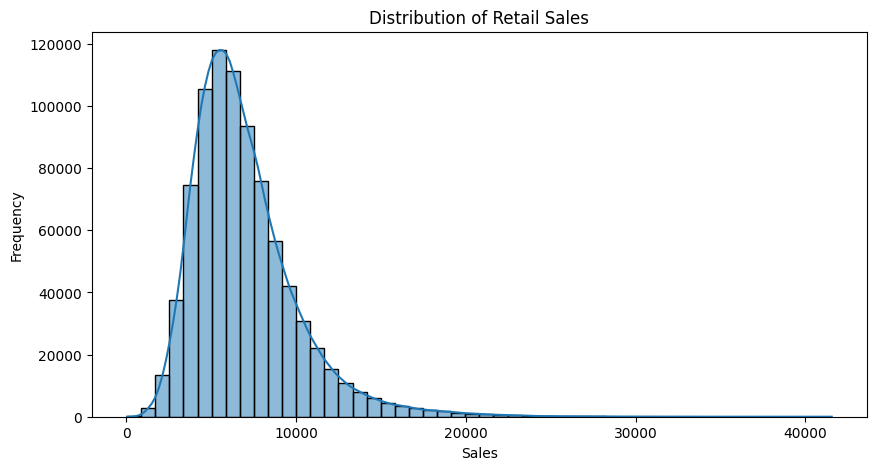

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df['Sales'],
    bins=50,
    kde=True
)

plt.title('Distribution of Retail Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

DAILY TOTAL SALES TREND

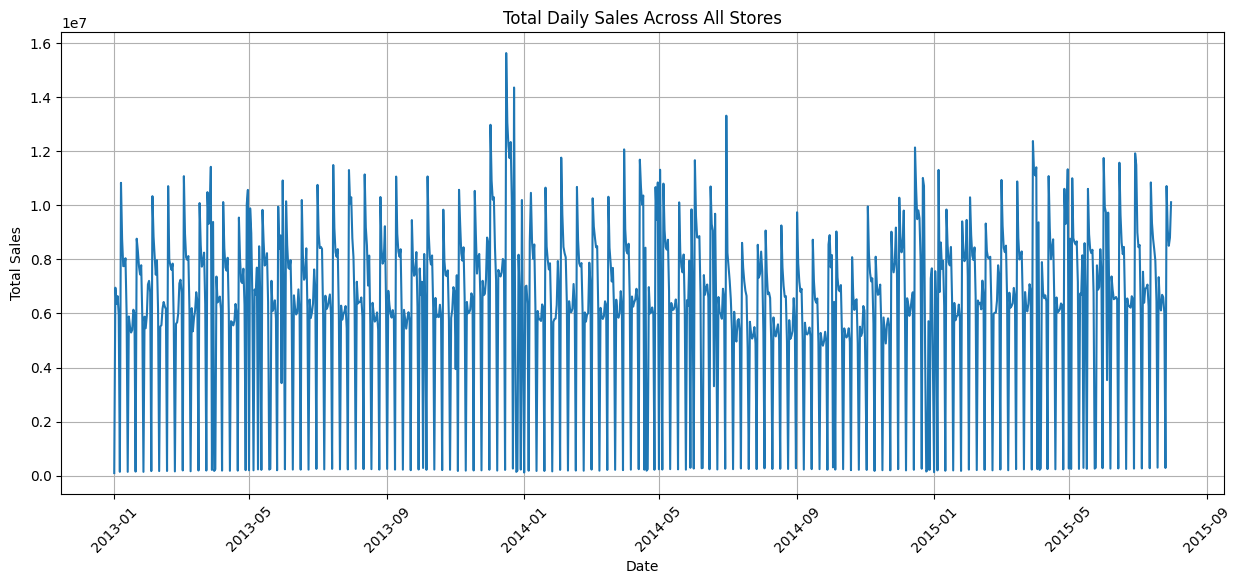

In [ ]:
daily_sales = eda_df.groupby('Date')['Sales'].sum()

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales.index,
    daily_sales.values
)

plt.title('Total Daily Sales Across All Stores')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

MONTHLY SALES ANALYSIS

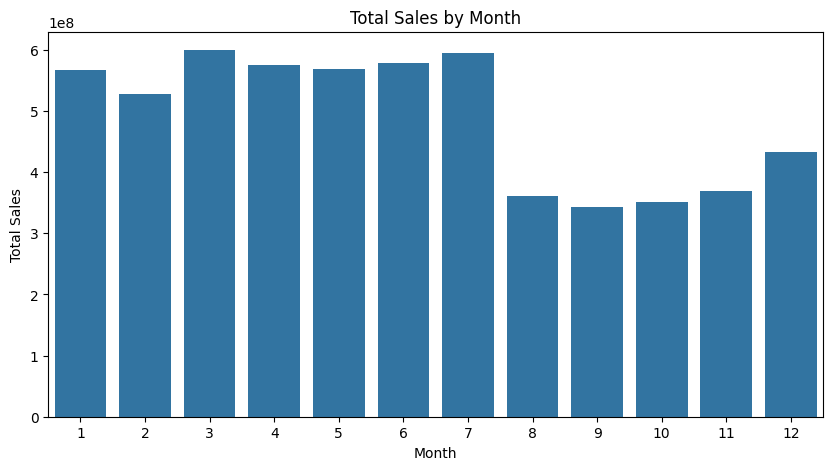

In [ ]:
monthly_sales = eda_df.groupby(
    'Month'
)['Sales'].sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.show()

YEAR WISE MONTHLY SALES

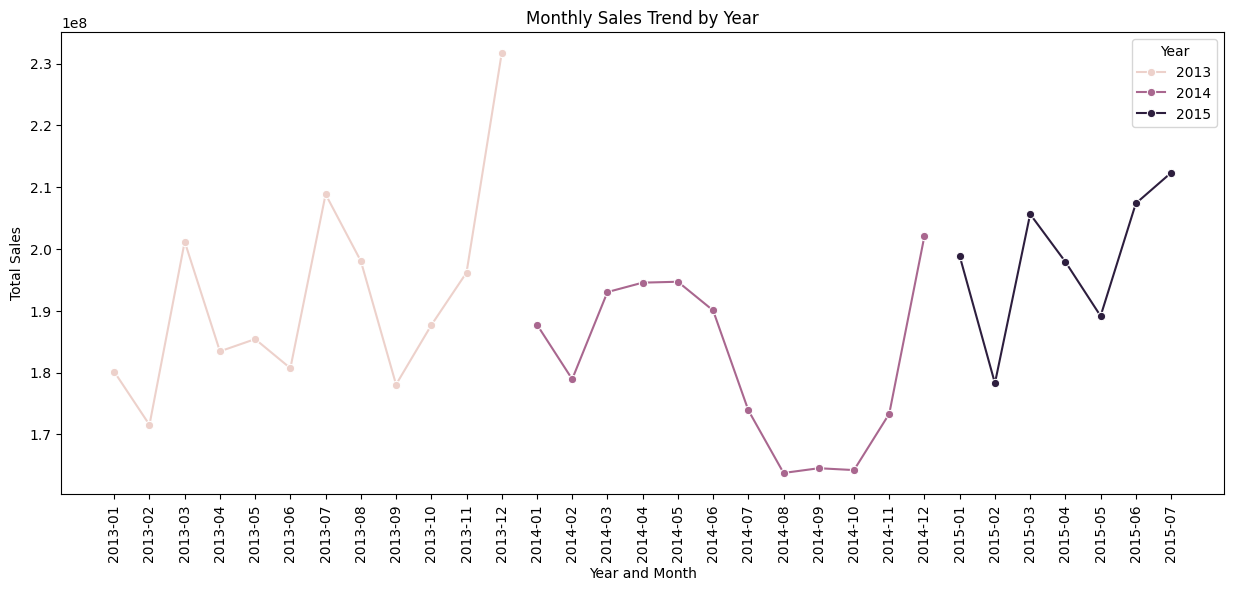

In [ ]:
year_month_sales = eda_df.groupby(
    ['Year', 'Month']
)['Sales'].sum().reset_index()

year_month_sales['YearMonth'] = (
    year_month_sales['Year'].astype(str)
    + '-'
    + year_month_sales['Month'].astype(str).str.zfill(2)
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=year_month_sales,
    x='YearMonth',
    y='Sales',
    hue='Year',
    marker='o'
)

plt.title('Monthly Sales Trend by Year')
plt.xlabel('Year and Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=90)
plt.show()

SALES BY WEEKDAY

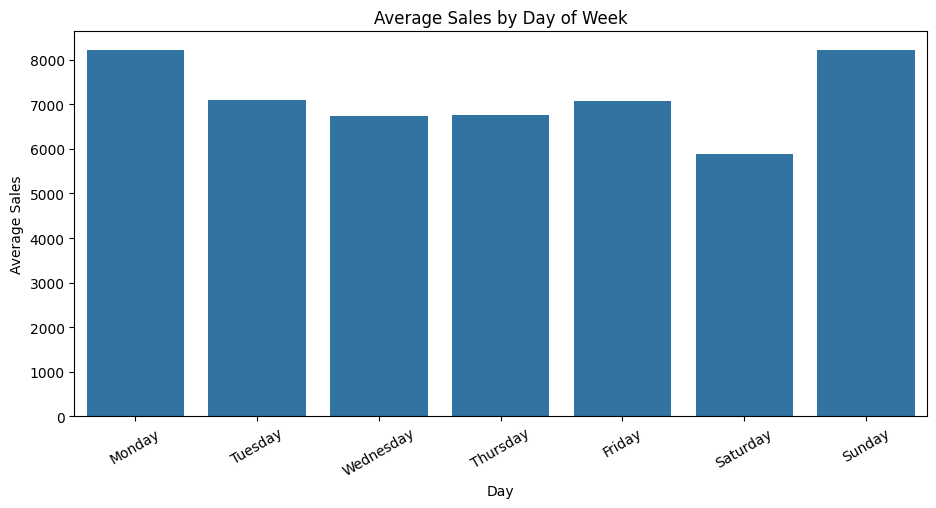

In [ ]:
weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_sales = eda_df.groupby(
    'DayName'
)['Sales'].mean().reindex(weekday_order)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title('Average Sales by Day of Week')
plt.xlabel('Day')
plt.ylabel('Average Sales')

plt.xticks(rotation=30)
plt.show()

COMPARING PROMOTIONAL AND NON-PROMOTIONAL SALES

In [ ]:
promo_sales = eda_df.groupby(
    'Promo'
)['Sales'].mean()

print("Average sales without promotion:",
      round(promo_sales.loc[0], 2))

print("Average sales with promotion:",
      round(promo_sales.loc[1], 2))

Average sales without promotion: 5929.83
Average sales with promotion: 8228.74


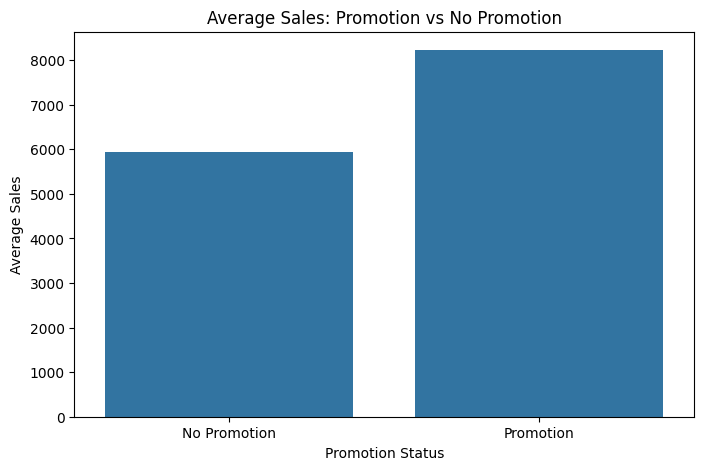

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=promo_sales.index,
    y=promo_sales.values
)

plt.xticks(
    [0, 1],
    ['No Promotion', 'Promotion']
)

plt.title('Average Sales: Promotion vs No Promotion')
plt.xlabel('Promotion Status')
plt.ylabel('Average Sales')

plt.show()

PROMOTIONAL UPLIFT

In [ ]:
sales_without_promo = promo_sales.loc[0]
sales_with_promo = promo_sales.loc[1]

promo_uplift = (
    (sales_with_promo - sales_without_promo)
    / sales_without_promo
) * 100

print("Promotion Sales Uplift:",
      round(promo_uplift, 2), "%")

Promotion Sales Uplift: 38.77 %


AVERAGE SALES BY STORE TYPE

In [ ]:
store_type_sales = eda_df.groupby(
    'StoreType'
)['Sales'].mean().sort_values(ascending=False)

print(store_type_sales)

StoreType
b    10233.380141
c     6933.126425
a     6925.697986
d     6822.300064
Name: Sales, dtype: float64


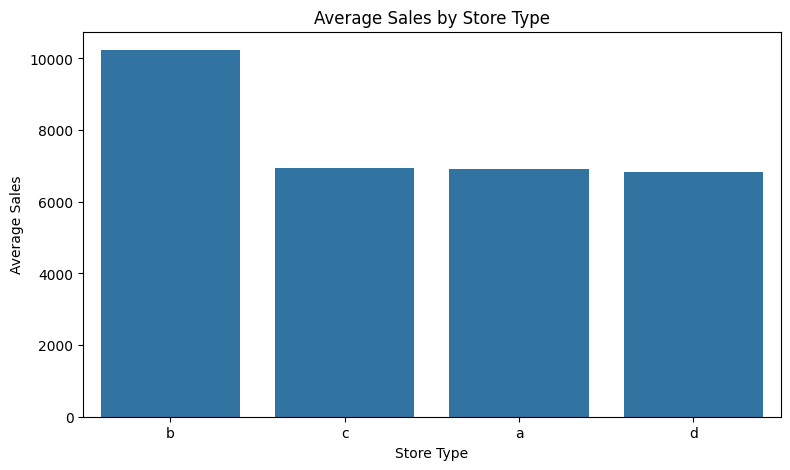

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=store_type_sales.index,
    y=store_type_sales.values
)

plt.title('Average Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales')

plt.show()

SCHOOL HOLIDAY SALES

In [ ]:
school_holiday_sales = eda_df.groupby(
    'SchoolHoliday'
)['Sales'].mean()

print("Average sales without school holiday:",
      round(school_holiday_sales.loc[0], 2))

print("Average sales during school holiday:",
      round(school_holiday_sales.loc[1], 2))

Average sales without school holiday: 6897.21
Average sales during school holiday: 7200.71


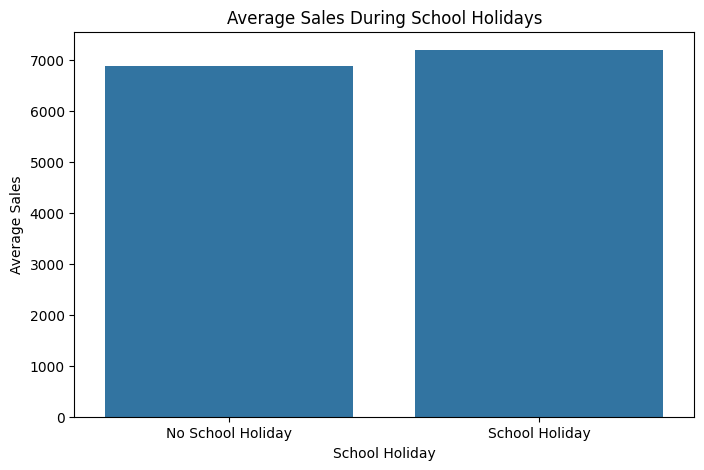

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=school_holiday_sales.index,
    y=school_holiday_sales.values
)

plt.xticks(
    [0, 1],
    ['No School Holiday', 'School Holiday']
)

plt.title('Average Sales During School Holidays')
plt.xlabel('School Holiday')
plt.ylabel('Average Sales')

plt.show()

EXPORT CSV

In [ ]:
eda_df.to_csv(
    '/content/rossmann_eda_cleaned.csv',
    index=False
)

print("EDA dataset saved successfully!")

EDA dataset saved successfully!


In [ ]:
from google.colab import files

files.download('/content/rossmann_eda_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TIME SERIES ANALYSIS

In [ ]:
# Select Store 1 directly from the original dataset
store_data = df.loc[
    df['Store'] == 1,
    ['Date', 'Sales']
].copy()

# Make sure Date is in datetime format
store_data['Date'] = pd.to_datetime(store_data['Date'])

# Make sure Sales is numeric
store_data['Sales'] = pd.to_numeric(store_data['Sales'])

# Sort dates
store_data = store_data.sort_values('Date')

# Set Date as index
store_data = store_data.set_index('Date')

# Check the data
display(store_data.head(10))

print(store_data['Sales'].describe())

,Sales
Date,
2013-01-01,0
2013-01-02,5530
2013-01-03,4327
2013-01-04,4486
2013-01-05,4997
2013-01-06,0
2013-01-07,7176
2013-01-08,5580
2013-01-09,5471


count     942.000000
mean     3945.704883
std      2015.417840
min         0.000000
25%      3588.250000
50%      4373.500000
75%      5220.000000
max      9528.000000
Name: Sales, dtype: float64


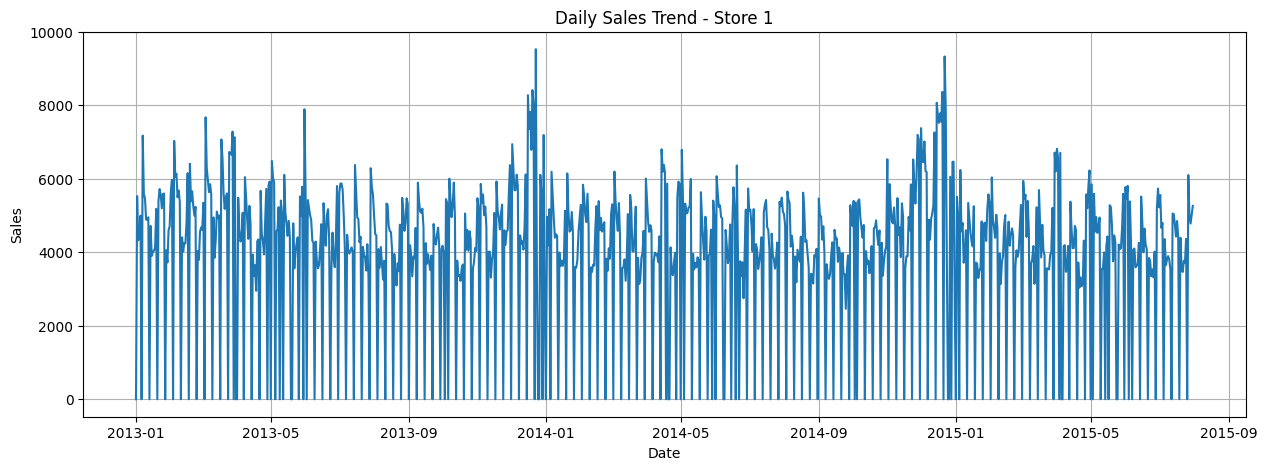

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(store_data.index, store_data['Sales'])

plt.title('Daily Sales Trend - Store 1')
plt.xlabel('Date')
plt.ylabel('Sales')

plt.grid(True)
plt.show()

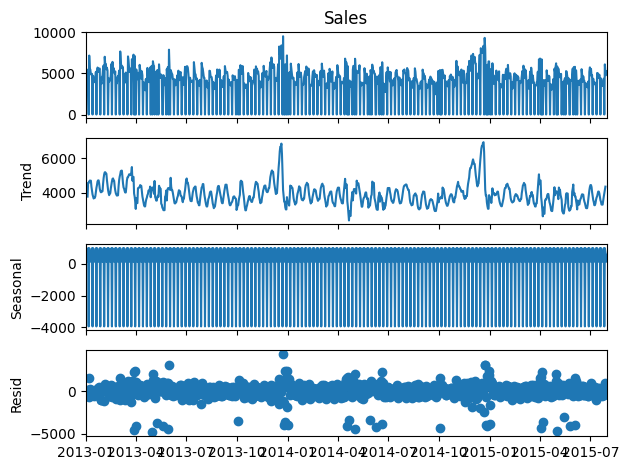

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    store_data['Sales'],
    model='additive',
    period=7
)

decomposition.plot()
plt.show()

In [ ]:
ADF TEST

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Perform the ADF test
adf_result = adfuller(store_data['Sales'].dropna())

# Display the results
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(key, ":", value)

# Interpret the result
if adf_result[1] <= 0.05:
    print("Result: Sales data is Stationary")
else:
    print("Result: Sales data is Non-Stationary")

ADF Statistic: -4.368104368168491
p-value: 0.00033788346141425444
Critical Values:
1% : -3.4374778690219956
5% : -2.864686684217556
10% : -2.5684454926748583
Result: Sales data is Stationary


/tmp/ipykernel_1323/2405159533.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(store_data['Sales'].dropna())


In [ ]:
ACF/PACF PLOTS

<Figure size 1200x500 with 0 Axes>

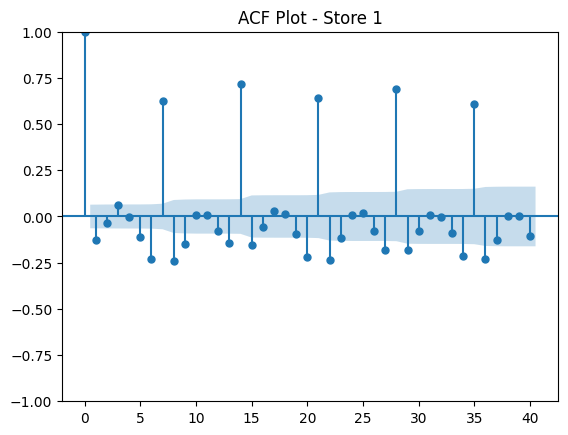

<Figure size 1200x500 with 0 Axes>

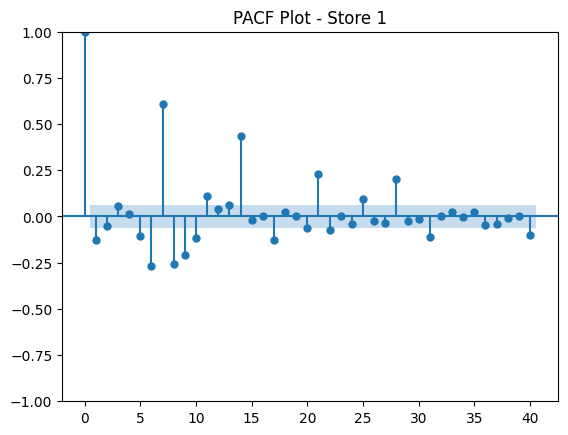

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ACF plot
plt.figure(figsize=(12, 5))
plot_acf(store_data['Sales'].dropna(), lags=40)
plt.title('ACF Plot - Store 1')
plt.show()

# PACF plot
plt.figure(figsize=(12, 5))
plot_pacf(store_data['Sales'].dropna(), lags=40, method='ywm')
plt.title('PACF Plot - Store 1')
plt.show()

VALIDATION STRATEGY

In [ ]:
# Define the training end date
train_end_date = '2015-05-31'

# Define the validation start date
validation_start_date = '2015-06-01'

# Create training dataset
train_data = store_data[
    store_data.index <= train_end_date
].copy()

# Create validation dataset
validation_data = store_data[
    store_data.index >= validation_start_date
].copy()

# Display dataset sizes
print("Training data shape:", train_data.shape)
print("Validation data shape:", validation_data.shape)

print("Training period:",
      train_data.index.min(), "to", train_data.index.max())

print("Validation period:",
      validation_data.index.min(), "to", validation_data.index.max())

Training data shape: (881, 1)
Validation data shape: (61, 1)
Training period: 2013-01-01 00:00:00 to 2015-05-31 00:00:00
Validation period: 2015-06-01 00:00:00 to 2015-07-31 00:00:00


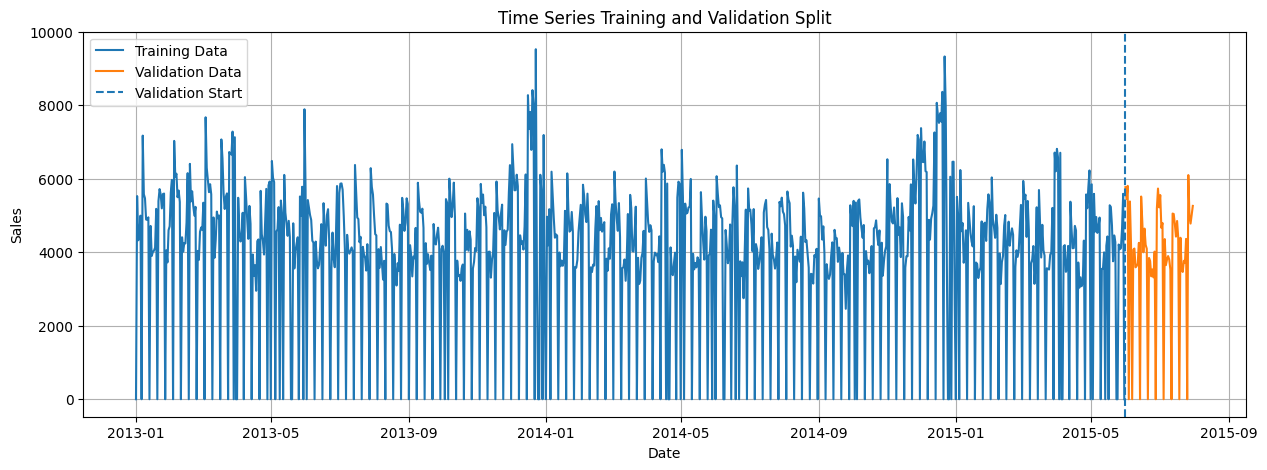

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(train_data.index, train_data['Sales'],
         label='Training Data')

plt.plot(validation_data.index, validation_data['Sales'],
         label='Validation Data')

plt.axvline(pd.Timestamp('2015-06-01'),
            linestyle='--',
            label='Validation Start')

plt.title('Time Series Training and Validation Split')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

BASELINE MODELS- NAIVE FORECAST MODEL

In [ ]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict validation sales using the previous day's actual sales
naive_predictions = train_data['Sales'].iloc[-1:].tolist() + \
                    validation_data['Sales'].iloc[:-1].tolist()

# Calculate MAE
naive_mae = mean_absolute_error(
    validation_data['Sales'],
    naive_predictions
)

# Calculate RMSE
naive_rmse = np.sqrt(
    mean_squared_error(
        validation_data['Sales'],
        naive_predictions
    )
)

# Display results
print("Naive Forecast MAE:", round(naive_mae, 2))
print("Naive Forecast RMSE:", round(naive_rmse, 2))

Naive Forecast MAE: 1730.44
Naive Forecast RMSE: 2681.26


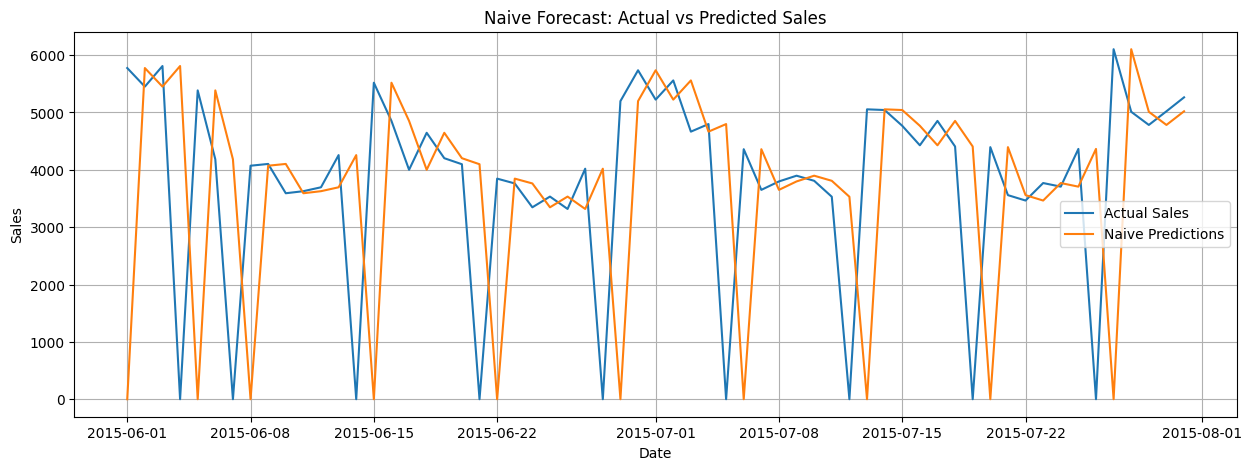

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    validation_data.index,
    validation_data['Sales'],
    label='Actual Sales'
)

plt.plot(
    validation_data.index,
    naive_predictions,
    label='Naive Predictions'
)

plt.title('Naive Forecast: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

AVERAGE FORCAST

In [ ]:
# Calculate the average sales of the last 7 days
last_7_days_average = train_data['Sales'].tail(7).mean()

# Predict sales for the validation period
moving_avg_predictions = [
    last_7_days_average
] * len(validation_data)

# Calculate MAE
moving_avg_mae = mean_absolute_error(
    validation_data['Sales'],
    moving_avg_predictions
)

# Calculate RMSE
moving_avg_rmse = np.sqrt(
    mean_squared_error(
        validation_data['Sales'],
        moving_avg_predictions
    )
)

# Display results
print("Moving Average MAE:", round(moving_avg_mae, 2))
print("Moving Average RMSE:", round(moving_avg_rmse, 2))

Moving Average MAE: 1510.21
Moving Average RMSE: 1807.35


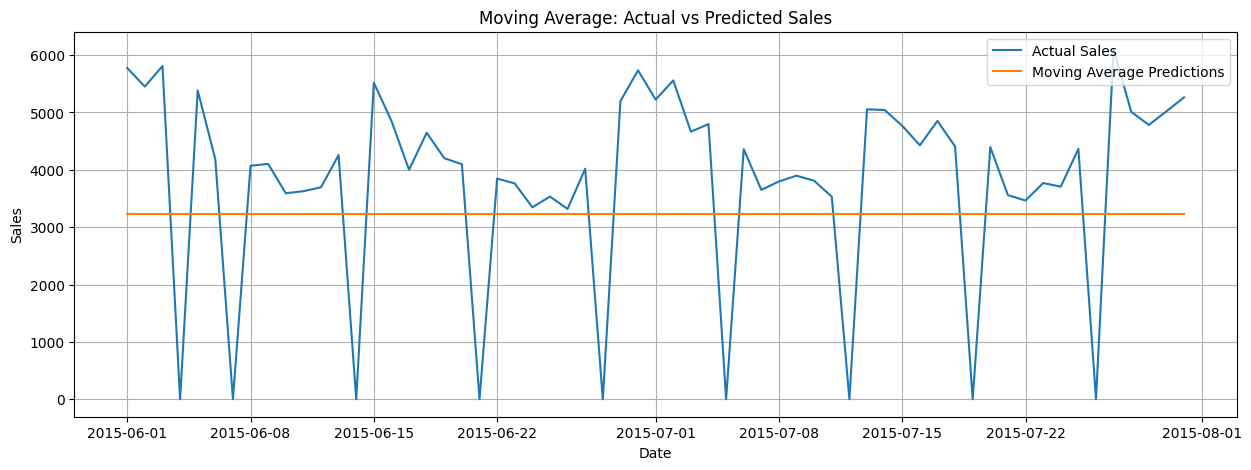

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    validation_data.index,
    validation_data['Sales'],
    label='Actual Sales'
)

plt.plot(
    validation_data.index,
    moving_avg_predictions,
    label='Moving Average Predictions'
)

plt.title('Moving Average: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
baseline_results = pd.DataFrame({
    'Model': ['Naive Forecast', 'Moving Average'],
    'MAE': [naive_mae, moving_avg_mae],
    'RMSE': [naive_rmse, moving_avg_rmse]
})

display(baseline_results)

,Model,MAE,RMSE
0,Naive Forecast,1730.442623,2681.260148
1,Moving Average,1510.210773,1807.348796


ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Build the ARIMA model
arima_model = ARIMA(
    train_data['Sales'],
    order=(1, 0, 1)
)

# Train the model
arima_fit = arima_model.fit()

# Forecast sales for the validation period
arima_predictions = arima_fit.forecast(
    steps=len(validation_data)
)

# Match predictions with validation dates
arima_predictions = pd.Series(
    np.asarray(arima_predictions),
    index=validation_data.index
)

print(arima_predictions.head())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Date
2015-06-01    4428.204979
2015-06-02    3992.460614
2015-06-03    3959.145150
2015-06-04    3956.597968
2015-06-05    3956.403219
dtype: float64


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_mae = mean_absolute_error(
    validation_data['Sales'],
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(
        validation_data['Sales'],
        arima_predictions
    )
)

print("ARIMA MAE:", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))

ARIMA MAE: 1169.95
ARIMA RMSE: 1720.18


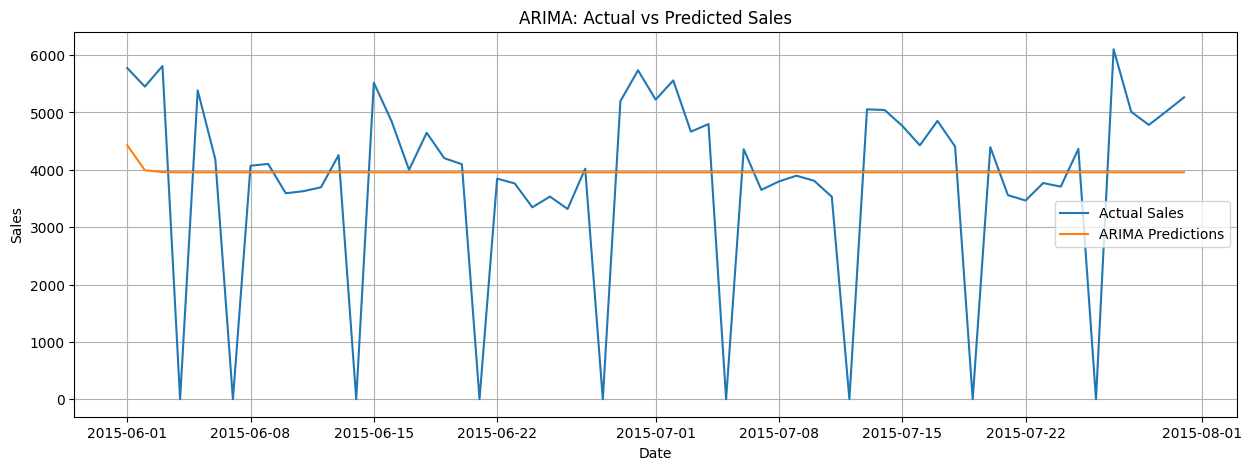

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    validation_data.index,
    validation_data['Sales'],
    label='Actual Sales'
)

plt.plot(
    validation_data.index,
    arima_predictions,
    label='ARIMA Predictions'
)

plt.title('ARIMA: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

SARIMA

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Build SARIMA model
sarima_model = SARIMAX(
    train_data['Sales'],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model
sarima_fit = sarima_model.fit(disp=False)

# Forecast validation period
sarima_predictions = sarima_fit.forecast(
    steps=len(validation_data)
)

# Match predictions with validation dates
sarima_predictions = pd.Series(
    np.asarray(sarima_predictions),
    index=validation_data.index
)

print(sarima_predictions.head())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Date
2015-06-01    4676.059033
2015-06-02    4447.400477
2015-06-03    4231.286511
2015-06-04    3897.462609
2015-06-05    4249.645255
dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
sarima_mae = mean_absolute_error(
    validation_data['Sales'],
    sarima_predictions
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        validation_data['Sales'],
        sarima_predictions
    )
)

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))

SARIMA MAE: 625.34
SARIMA RMSE: 864.26


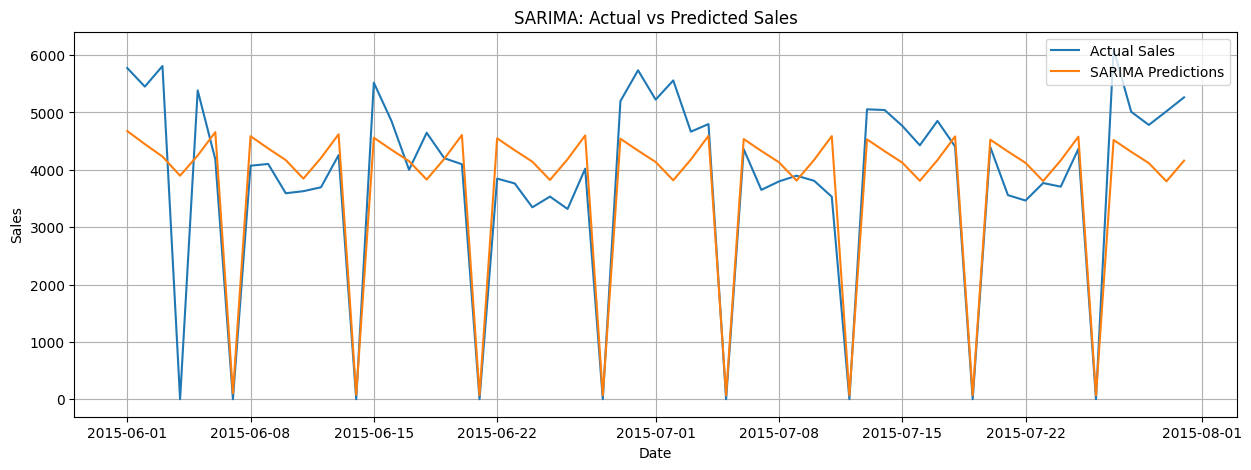

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    validation_data.index,
    validation_data['Sales'],
    label='Actual Sales'
)

plt.plot(
    validation_data.index,
    sarima_predictions,
    label='SARIMA Predictions'
)

plt.title('SARIMA: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
FEATURE ENGINEERING

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

display(df[['Date', 'Year', 'Month', 'Day',
            'DayOfWeek', 'WeekOfYear']].head())

,Date,Year,Month,Day,DayOfWeek,WeekOfYear
0,2015-07-31,2015,7,31,4,31
1,2015-07-31,2015,7,31,4,31
2,2015-07-31,2015,7,31,4,31
3,2015-07-31,2015,7,31,4,31
4,2015-07-31,2015,7,31,4,31


In [ ]:
df[['Promo', 'StateHoliday', 'SchoolHoliday']].head()

,Promo,StateHoliday,SchoolHoliday
0,1,0,1
1,1,0,1
2,1,0,1
3,1,0,1
4,1,0,1


In [ ]:
# Convert StateHoliday into numeric categories

df['StateHoliday'] = df['StateHoliday'].astype(str)

df['StateHoliday'] = df['StateHoliday'].map({
    '0': 0,
    'a': 1,
    'b': 2,
    'c': 3
})

# Ensure promotion and school holiday are numeric

df['Promo'] = df['Promo'].astype(int)

df['SchoolHoliday'] = df['SchoolHoliday'].astype(int)

# Check the result

display(df[['Promo', 'StateHoliday', 'SchoolHoliday']].head())

,Promo,StateHoliday,SchoolHoliday
0,1,0.0,1
1,1,0.0,1
2,1,0.0,1
3,1,0.0,1
4,1,0.0,1


In [ ]:
# Sort data by store and date
df = df.sort_values(['Store', 'Date'])

# Previous day's sales
df['Sales_Lag_1'] = df.groupby('Store')['Sales'].shift(1)

# Sales from 7 days ago
df['Sales_Lag_7'] = df.groupby('Store')['Sales'].shift(7)

# Display the new features
display(df[['Store', 'Date', 'Sales',
            'Sales_Lag_1', 'Sales_Lag_7']].head(10))

,Store,Date,Sales,Sales_Lag_1,Sales_Lag_7
1016095,1,2013-01-01,0,NaN,NaN
1014980,1,2013-01-02,5530,0.0,NaN
1013865,1,2013-01-03,4327,5530.0,NaN
1012750,1,2013-01-04,4486,4327.0,NaN
1011635,1,2013-01-05,4997,4486.0,NaN
1010520,1,2013-01-06,0,4997.0,NaN
1009405,1,2013-01-07,7176,0.0,NaN
1008290,1,2013-01-08,5580,7176.0,0.0
1007175,1,2013-01-09,5471,5580.0,5530.0
1006060,1,2013-01-10,4892,5471.0,4327.0


In [ ]:
# Calculate the previous 7-day average sales
df['Sales_Rolling_Mean_7'] = (
    df.groupby('Store')['Sales']
      .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

# Display the result
display(df[['Store', 'Date', 'Sales',
            'Sales_Rolling_Mean_7']].head(15))

,Store,Date,Sales,Sales_Rolling_Mean_7
1016095,1,2013-01-01,0,NaN
1014980,1,2013-01-02,5530,NaN
1013865,1,2013-01-03,4327,NaN
1012750,1,2013-01-04,4486,NaN
1011635,1,2013-01-05,4997,NaN
1010520,1,2013-01-06,0,NaN
1009405,1,2013-01-07,7176,NaN
1008290,1,2013-01-08,5580,3788.000000
1007175,1,2013-01-09,5471,4585.142857
1006060,1,2013-01-10,4892,4576.714286


In [ ]:
# Check missing values in newly created features

print(df[['Sales_Lag_1',
          'Sales_Lag_7',
          'Sales_Rolling_Mean_7']].isnull().sum())

Sales_Lag_1             1115
Sales_Lag_7             7805
Sales_Rolling_Mean_7    7805
dtype: int64


In [ ]:
df = df.dropna(
    subset=[
        'Sales_Lag_1',
        'Sales_Lag_7',
        'Sales_Rolling_Mean_7'
    ]
)

df = df.reset_index(drop=True)

print("Updated dataset shape:", df.shape)

Updated dataset shape: (1009404, 25)


LIGHT GBM

In [ ]:
!pip install lightgbm

In [ ]:
import lightgbm as lgb

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd


In [ ]:
# Training data
ml_train = df[df['Date'] <= '2015-05-31'].copy()

# Validation data
ml_validation = df[
    (df['Date'] >= '2015-06-01') &
    (df['Date'] <= '2015-07-31')
].copy()

print("Training shape:", ml_train.shape)
print("Validation shape:", ml_validation.shape)

Training shape: (941389, 25)
Validation shape: (68015, 25)


In [ ]:
# Select input features
features = [
    'Store',
    'Year',
    'Month',
    'Day',
    'DayOfWeek',
    'WeekOfYear',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'Sales_Lag_1',
    'Sales_Lag_7',
    'Sales_Rolling_Mean_7'
]

# Target variable
target = 'Sales'

# Create training features and target
X_train = ml_train[features]
y_train = ml_train[target]

# Create validation features and target
X_validation = ml_validation[features]
y_validation = ml_validation[target]

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Validation features:", X_validation.shape)
print("Validation target:", y_validation.shape)

Training features: (941389, 12)
Training target: (941389,)
Validation features: (68015, 12)
Validation target: (68015,)


In [ ]:
# Create LightGBM model
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42
)

# Train the model
lgb_model.fit(X_train, y_train)

print("LightGBM model training completed!")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.831504 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1135
[LightGBM] [Info] Number of data points in the train set: 941389, number of used features: 12
[LightGBM] [Info] Start training from score 5753.767386
LightGBM model training completed!


In [ ]:
# Predict sales
lgb_predictions = lgb_model.predict(X_validation)

# Prevent negative sales predictions
lgb_predictions = np.maximum(lgb_predictions, 0)

# Display first 10 predictions
print("Predicted Sales:")
print(lgb_predictions[:10])

Predicted Sales:
[8727.26189866 6033.80736484 5814.10727819  165.4721395  5198.46119646
 4861.98159119    0.         3765.03479554 3761.06295006 4110.83121822]


METRICS

In [ ]:
# Calculate MAE
lgb_mae = mean_absolute_error(
    y_validation,
    lgb_predictions
)

# Calculate RMSE
lgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        lgb_predictions
    )
)

print("LightGBM MAE:", round(lgb_mae, 2))
print("LightGBM RMSE:", round(lgb_rmse, 2))

LightGBM MAE: 618.5
LightGBM RMSE: 979.1


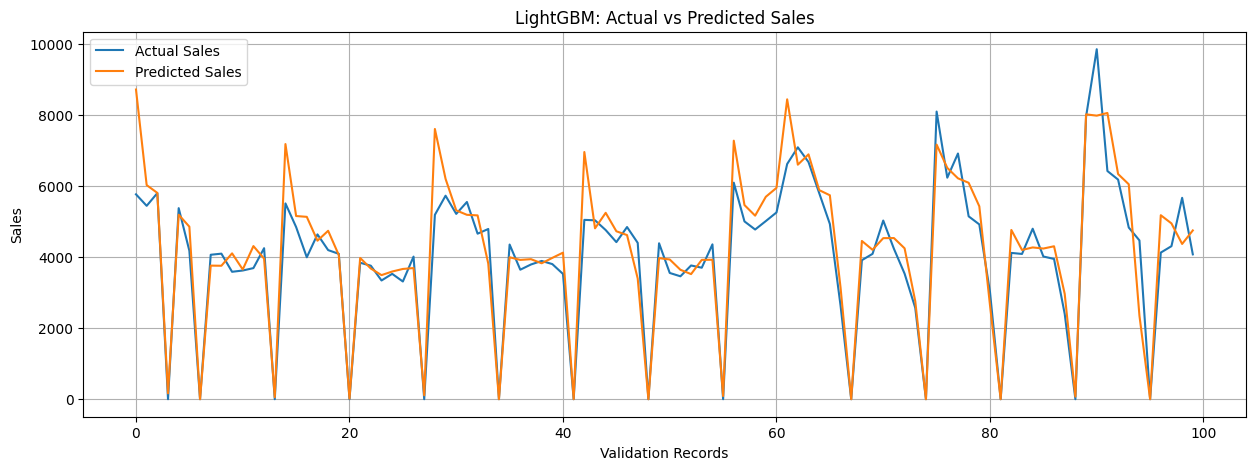

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    y_validation.values[:100],
    label='Actual Sales'
)

plt.plot(
    lgb_predictions[:100],
    label='Predicted Sales'
)

plt.title('LightGBM: Actual vs Predicted Sales')
plt.xlabel('Validation Records')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

COMPARING ALL MODELS

In [ ]:
# Select Store 1 validation records
store1_mask = ml_validation['Store'].eq(1).to_numpy()

store1_actual = y_validation.to_numpy()[store1_mask]
store1_predictions = lgb_predictions[store1_mask]

# Calculate metrics
lgb_store1_mae = mean_absolute_error(
    store1_actual,
    store1_predictions
)

lgb_store1_rmse = np.sqrt(
    mean_squared_error(
        store1_actual,
        store1_predictions
    )
)

print("LightGBM Store 1 MAE:", round(lgb_store1_mae, 2))
print("LightGBM Store 1 RMSE:", round(lgb_store1_rmse, 2))

LightGBM Store 1 MAE: 456.83
LightGBM Store 1 RMSE: 722.91


In [ ]:
model_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'Moving Average',
        'ARIMA',
        'SARIMA',
        'LightGBM'
    ],
    'MAE': [
        naive_mae,
        moving_avg_mae,
        arima_mae,
        sarima_mae,
        lgb_store1_mae
    ],
    'RMSE': [
        naive_rmse,
        moving_avg_rmse,
        arima_rmse,
        sarima_rmse,
        lgb_store1_rmse
    ]
})

display(model_comparison.sort_values('MAE'))

,Model,MAE,RMSE
4,LightGBM,456.830496,722.906608
3,SARIMA,625.338542,864.259578
2,ARIMA,1169.951808,1720.182561
1,Moving Average,1510.210773,1807.348796
0,Naive Forecast,1730.442623,2681.260148


SIX WEEKS SALES FORCASTING

In [ ]:
# Use all available historical data
X_final = df[features]
y_final = df['Sales']

# Create the final LightGBM model
final_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    random_state=42
)

# Train using all historical data
final_model.fit(X_final, y_final)

print("Final LightGBM model trained successfully!")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.540222 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1135
[LightGBM] [Info] Number of data points in the train set: 1009404, number of used features: 12
[LightGBM] [Info] Start training from score 5781.846827
Final LightGBM model trained successfully!


In [ ]:
# Load the test dataset
test = pd.read_csv(
    '/content/rossmann_data/test.csv'
)

# Convert Date into datetime format
test['Date'] = pd.to_datetime(test['Date'])

# Find the last date in historical training data
last_date = df['Date'].max()

# Select the next 42 days
forecast_end = last_date + pd.Timedelta(days=42)

future_data = test[
    (test['Date'] > last_date) &
    (test['Date'] <= forecast_end)
].copy()

# Sort by date and store
future_data = future_data.sort_values(
    ['Date', 'Store']
).reset_index(drop=True)

print("Forecast start:", future_data['Date'].min())
print("Forecast end:", future_data['Date'].max())
print("Number of forecast days:",
      future_data['Date'].nunique())

display(future_data.head())

Forecast start: 2015-08-01 00:00:00
Forecast end: 2015-09-11 00:00:00
Number of forecast days: 42


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,40233,1,6,2015-08-01,1.0,0,0,1
1,40234,3,6,2015-08-01,1.0,0,0,0
2,40235,7,6,2015-08-01,1.0,0,0,0
3,40236,8,6,2015-08-01,1.0,0,0,0
4,40237,9,6,2015-08-01,1.0,0,0,0


In [ ]:
# Create date features
future_data['Year'] = future_data['Date'].dt.year

future_data['Month'] = future_data['Date'].dt.month

future_data['Day'] = future_data['Date'].dt.day

future_data['DayOfWeek'] = future_data['Date'].dt.dayofweek

future_data['WeekOfYear'] = (
    future_data['Date'].dt.isocalendar().week.astype(int)
)

# Convert StateHoliday into numeric categories
future_data['StateHoliday'] = (
    future_data['StateHoliday'].astype(str).map({
        '0': 0,
        'a': 1,
        'b': 2,
        'c': 3
    })
)

# Convert promotion and school holiday columns
future_data['Promo'] = future_data['Promo'].astype(int)

future_data['SchoolHoliday'] = (
    future_data['SchoolHoliday'].astype(int)
)

display(future_data.head())

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear
0,40233,1,5,2015-08-01,1.0,0,0,1,2015,8,1,31
1,40234,3,5,2015-08-01,1.0,0,0,0,2015,8,1,31
2,40235,7,5,2015-08-01,1.0,0,0,0,2015,8,1,31
3,40236,8,5,2015-08-01,1.0,0,0,0,2015,8,1,31
4,40237,9,5,2015-08-01,1.0,0,0,0,2015,8,1,31


In [ ]:
# Merge store information into future data
future_data = future_data.merge(
    store,
    on='Store',
    how='left'
)

# Sort future data
future_data = future_data.sort_values(
    ['Store', 'Date']
).reset_index(drop=True)

# Store historical sales for each store
historical_sales = {
    store_id: list(group.sort_values('Date')['Sales'])
    for store_id, group in df.groupby('Store')
}

forecast_results = []

# Generate predictions day by day
for date in sorted(future_data['Date'].unique()):

    daily_data = future_data[
        future_data['Date'] == date
    ].copy()

    daily_predictions = []

    for index, row in daily_data.iterrows():

        sales_history = historical_sales.get(
            row['Store'], []
        )

        lag_1 = sales_history[-1] if len(sales_history) >= 1 else 0

        lag_7 = sales_history[-7] if len(sales_history) >= 7 else 0

        rolling_mean = (
            np.mean(sales_history[-7:])
            if len(sales_history) >= 7 else np.mean(sales_history)
        )

        input_data = pd.DataFrame([{
            'Store': row['Store'],
            'Year': row['Year'],
            'Month': row['Month'],
            'Day': row['Day'],
            'DayOfWeek': row['DayOfWeek'],
            'WeekOfYear': row['WeekOfYear'],
            'Promo': row['Promo'],
            'StateHoliday': row['StateHoliday'],
            'SchoolHoliday': row['SchoolHoliday'],
            'Sales_Lag_1': lag_1,
            'Sales_Lag_7': lag_7,
            'Sales_Rolling_Mean_7': rolling_mean
        }])

        prediction = max(
            0,
            final_model.predict(input_data)[0]
        )

        daily_predictions.append(prediction)

        historical_sales[row['Store']].append(prediction)

    daily_data['Predicted_Sales'] = daily_predictions

    forecast_results.append(daily_data)

# Combine all predictions
forecast_df = pd.concat(
    forecast_results,
    ignore_index=True
)

display(forecast_df[
    ['Store', 'Date', 'Predicted_Sales']
].head(10))

,Store,Date,Predicted_Sales
0,1,2015-08-01,4594.362967
1,3,2015-08-01,4675.007474
2,7,2015-08-01,8293.731669
3,8,2015-08-01,3716.036599
4,9,2015-08-01,6138.374137
5,10,2015-08-01,4938.135144
6,11,2015-08-01,5200.213532
7,12,2015-08-01,6010.795353
8,13,2015-08-01,5082.807943
9,14,2015-08-01,3377.456149


TOTAL PREDICTED SALES BY STORE

In [ ]:
store_forecast = forecast_df.groupby('Store')['Predicted_Sales'].sum().reset_index()

store_forecast = store_forecast.sort_values(
    'Predicted_Sales',
    ascending=False
)

display(store_forecast.head(10))

,Store,Predicted_Sales
201,262,860884.532530
854,1114,769156.761165
433,562,726893.422681
646,842,724297.819438
193,251,640361.696666
567,733,637827.346297
256,335,585983.018838
293,383,566233.912598
584,756,562709.162612
200,259,540416.763632


DAILY PREDICTED SALES

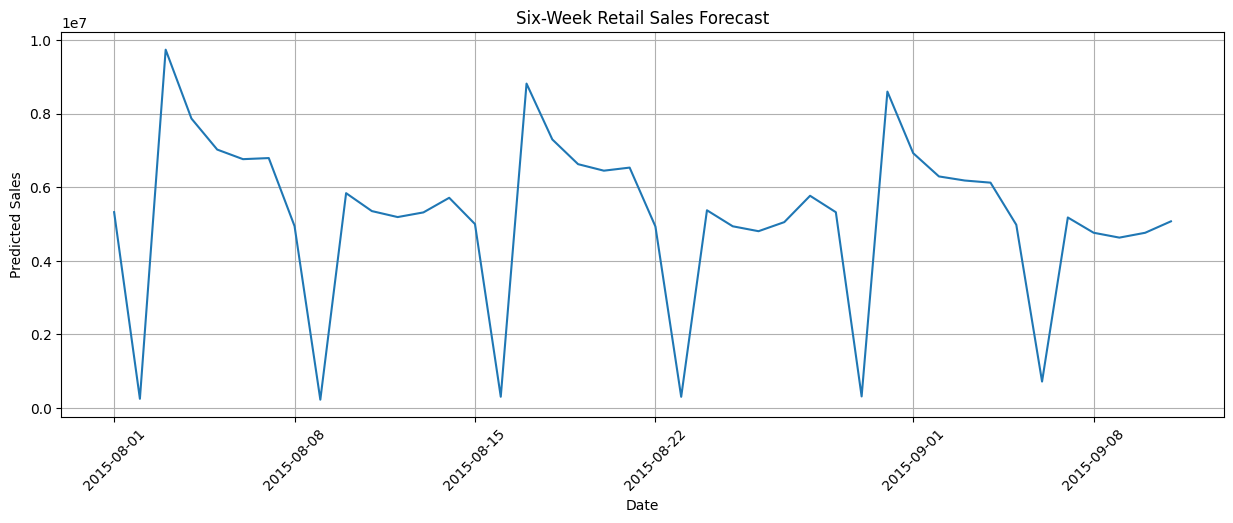

In [ ]:
daily_forecast = forecast_df.groupby('Date')['Predicted_Sales'].sum().reset_index()

plt.figure(figsize=(15, 5))

plt.plot(
    daily_forecast['Date'],
    daily_forecast['Predicted_Sales']
)

plt.title('Six-Week Retail Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Predicted Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

EXPORT CSV

In [ ]:
forecast_df.to_csv(
    'six_week_sales_forecast.csv',
    index=False
)

from google.colab import files
files.download('six_week_sales_forecast.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

INVENTORY INSIGHTS

TOTAL AND AVERAGE DEMAND PER STORE

In [ ]:
inventory_insights = forecast_df.groupby('Store').agg(
    Total_Forecast_Sales=('Predicted_Sales', 'sum'),
    Average_Daily_Sales=('Predicted_Sales', 'mean')
).reset_index()

inventory_insights = inventory_insights.sort_values(
    'Total_Forecast_Sales',
    ascending=False
)

display(inventory_insights.head(10))

,Store,Total_Forecast_Sales,Average_Daily_Sales
201,262,860884.532530,20497.250775
854,1114,769156.761165,18313.256218
433,562,726893.422681,17306.986254
646,842,724297.819438,17245.186177
193,251,640361.696666,15246.707063
567,733,637827.346297,15186.365388
256,335,585983.018838,13951.976639
293,383,566233.912598,13481.759824
584,756,562709.162612,13397.837205
200,259,540416.763632,12867.065801


In [ ]:
inventory_insights.to_csv(
    'inventory_insights.csv',
    index=False
)

files.download('inventory_insights.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>